# Домашнее задание 1: персональные top-10 рекомендации

**Богодяж Юлия Олеговна**

Датасет: **Online Retail**, UCI Machine Learning Repository. [Первоисточник](https://archive.ics.uci.edu/dataset/352/online+retail), [DOI](https://doi.org/10.24432/C5BW33).

Задача — предложить покупателю десять **ещё не купленных** товаров из известного каталога.
Взаимодействие — строка успешной покупки товара; повторные покупки одной пары сохраняются как события.
Релевантность во всех экспериментах: товар действительно куплен пользователем в будущем окне, независимо от количества и обучающего таргета.
Это задача открытия новых товаров, поэтому повторные покупки не входят в ground truth.

Сравниваются ItemKNN, iALS, EASE, FM с метаданными и iALS с собственным таргетом.
Все пять методов реализованы в `models/`; готовые рекомендательные библиотеки не используются.

## Как повторить

Требуется Python 3.12 и примерно 2–4 GB свободной RAM. Из корня репозитория:

```bash
python3.12 -m venv .venv
source .venv/bin/activate
pip install -r requirements.txt
python -m unittest discover -s tests -v
python scripts/run_notebook.py
```

Последняя команда **выполняет весь ноутбук**, включая подбор и финальный test, и сохраняет outputs.
Данные (архив 22.6 MB) скачиваются автоматически с UCI в локальный `data/`; при первом запуске нужен интернет.
Можно открыть этот ноутбук в Jupyter/VS Code и выбрать Python из `.venv`, затем Run All.
Файлы результатов и рисунки перезаписываются при новом полном запуске. Данные и веса в GitHub не загружаются.

In [1]:
import os
os.environ.setdefault('MPLCONFIGDIR', str(__import__('pathlib').Path('data/matplotlib').resolve()))
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
import sys, json, time, random, platform, importlib.metadata
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
from data_utils import (load_data, clean_data, build_training, make_evaluation, FeatureEncoder,
                        TRAIN_END, VALIDATION_END, SEED)
from models import ItemKNN, ImplicitALS, EASE, FactorizationMachine, RecencyFrequencyALS
from evaluation import evaluate, paired_bootstrap

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
thread_limit = threadpool_limits(limits=1)
for folder in ['results', 'figures']:
    Path(folder).mkdir(exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
pd.set_option('display.max_colwidth', 100)
versions = {name: importlib.metadata.version(name) for name in
            ['numpy', 'scipy', 'pandas', 'torch', 'matplotlib', 'nbformat', 'nbclient']}
environment = {'python': sys.version, 'platform': platform.platform(), 'seed': SEED,
               'threads': 1, 'packages': versions}
Path('results/environment.json').write_text(json.dumps(environment, ensure_ascii=False, indent=2))
display(pd.Series(versions, name='version').to_frame())

,version
numpy,2.3.5
scipy,1.16.3
pandas,2.2.3
torch,2.7.1
matplotlib,3.10.3
nbformat,5.10.4
nbclient,0.10.2


## 1. Загрузка и описание данных

Chen, D. (2015). Online Retail [Dataset]. UCI. Лицензия данных — [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
Это покупки британского интернет-магазина подарков за 01.12.2010–09.12.2011; среди клиентов есть оптовики.
Исходный объём по UCI — 541 909 строк. Используется весь очищенный набор, без случайной подвыборки и без k-core по будущим событиям.
Архив проверяется по SHA256: изменение первоисточника приводит к явной ошибке.

| Поле | Смысл и использование |
|---|---|
| CustomerID | Анонимный идентификатор покупателя; ось user |
| StockCode | Код товара; ось item |
| InvoiceNo | Счёт, префикс C означает отмену; число отдельных счетов — частота покупок |
| InvoiceDate | Время события; разбиение и custom target |
| Quantity | Количество единиц; только проверка успешной покупки, не вес предпочтения оптовика |
| UnitPrice | Цена за единицу в GBP; только историческая медиана для FM |
| Description | Название товара; токены для FM |
| Country | Страна покупателя из его последнего исторического заказа; FM |

In [2]:
raw, manifest = load_data()
data, cleaning = clean_data(raw)
manifest.update(raw_rows=len(raw), clean_rows=len(data), users=data.CustomerID.nunique(),
                items=data.StockCode.nunique(), unique_pairs=len(data[['CustomerID', 'StockCode']].drop_duplicates()),
                start=str(data.InvoiceDate.min()), end=str(data.InvoiceDate.max()))
Path('results/data_manifest.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=2))
display(pd.Series(manifest, name='value').to_frame())

,value
source,https://archive.ics.uci.edu/dataset/352/online+retail
download,https://archive.ics.uci.edu/static/public/352/online+retail.zip
archive_sha256,f5385cbb54bbebf7196389109c6b0621faab0c304e3702548165e71c84aede8b
raw_rows,541909
clean_rows,391150
users,4334
items,3659
unique_pairs,266221
start,2010-12-01 08:26:00
end,2011-12-09 12:50:00


## 2. EDA и подготовка

Покупки без CustomerID нельзя персонализировать. Удаляем их, отмены, неположительные цену/количество,
служебные коды доставки и комиссий (оставляем SKU по шаблону `\d{5}[A-Za-z]{0,2}`), точные дубликаты строк.
Повторы одной user-item пары в разных счетах **не** удаляем: они нужны для анализа частоты.
Отсутствующие названия заменяем пустой строкой; для FM это нулевой текстовый вектор.
Правило SKU — приближение: оно может исключить нестандартно закодированный реальный товар.
Возвраты исключены как события; мы не используем будущие возвраты для изменения прошлой покупки.

Ниже — фактические пропуски в файле, даже если краткая карточка UCI не отмечает их наличие.

,missing,fraction
InvoiceNo,0,0.000000
StockCode,0,0.000000
Description,1454,0.002683
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
CustomerID,135080,0.249267
Country,0,0.000000


,step,rows,removed
0,Исходные строки,541909,0
1,Есть user/item/time,406829,135080
2,Без отменённых счетов,397924,8905
3,Положительные количество и цена,397884,40
4,Товарные SKU (без доставки/комиссий),396337,1547
5,Без точных дубликатов строк,391150,5187


,user_unique_items,item_unique_users
count,4334.000000,3659.000000
mean,61.426165,72.757857
std,85.307437,91.577051
min,1.000000,1.000000
25%,16.000000,11.000000
50%,35.000000,40.000000
75%,77.000000,100.000000
max,1785.000000,881.000000


Разреженность матрицы уникальных пар: 98.3212%
Доля событий сверх первого события user-item: 31.94%


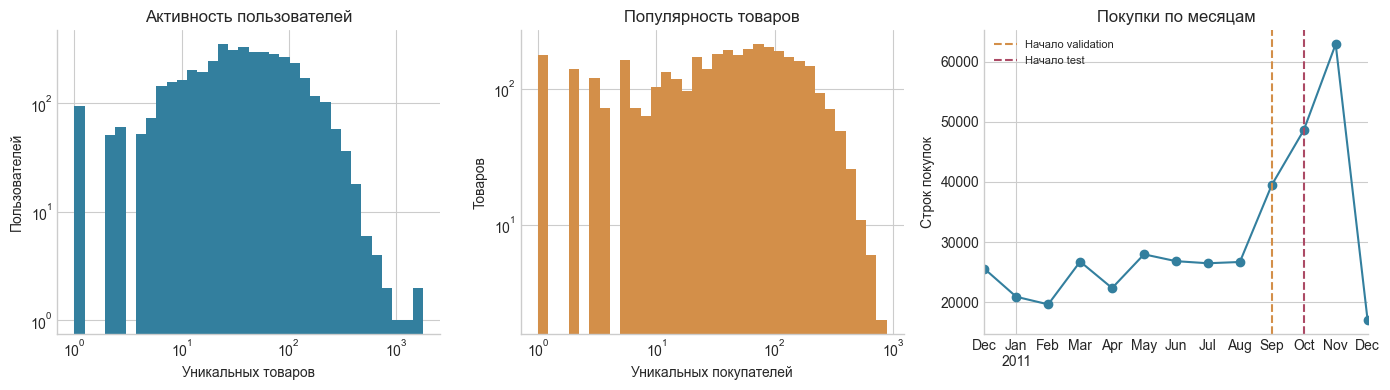

In [3]:
missing = raw.isna().sum().rename('missing').to_frame()
missing['fraction'] = missing['missing'] / len(raw)
display(missing)
display(cleaning)
cleaning.to_csv('results/cleaning.csv', index=False)
pair_count = len(data[['CustomerID', 'StockCode']].drop_duplicates())
activity = data.groupby('CustomerID').StockCode.nunique()
popularity = data.groupby('StockCode').CustomerID.nunique()
sparsity = 1 - pair_count / (activity.size * popularity.size)
display(pd.DataFrame({'user_unique_items': activity.describe(),
                      'item_unique_users': popularity.describe()}))
print(f'Разреженность матрицы уникальных пар: {sparsity:.4%}')
print(f'Доля событий сверх первого события user-item: {1-pair_count/len(data):.2%}')

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(activity, bins=np.geomspace(1, activity.max()+1, 35), color='#337f9e')
axes[0].set(xscale='log', yscale='log', title='Активность пользователей', xlabel='Уникальных товаров', ylabel='Пользователей')
axes[1].hist(popularity, bins=np.geomspace(1, popularity.max()+1, 35), color='#d38f49')
axes[1].set(xscale='log', yscale='log', title='Популярность товаров', xlabel='Уникальных покупателей', ylabel='Товаров')
data.set_index('InvoiceDate').resample('MS').size().plot(ax=axes[2], color='#337f9e', marker='o')
axes[2].axvline(TRAIN_END, color='#d38f49', linestyle='--', label='Начало validation')
axes[2].axvline(VALIDATION_END, color='#ac4a65', linestyle='--', label='Начало test')
axes[2].set(title='Покупки по месяцам', xlabel='', ylabel='Строк покупок')
axes[2].legend(fontsize=8)
fig.tight_layout()
fig.savefig('figures/eda_activity.png', dpi=160)
plt.show()

,value
train_description_missing,0.00
train_description_variants,3524.00
train_countries,36.00
train_price_median_GBP,1.95
train_price_p99_GBP,12.75
train_products_with_changing_descriptions,143.00


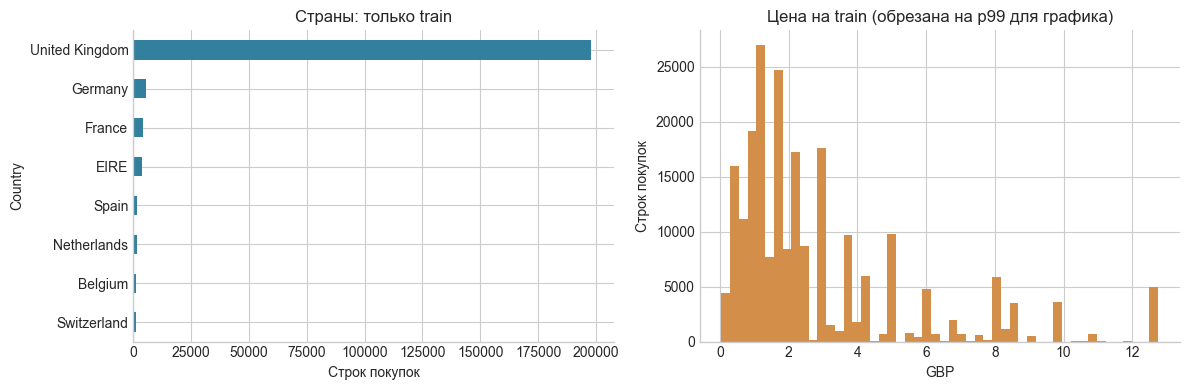

In [4]:
train_rows = data[data.InvoiceDate < TRAIN_END].copy()
validation_rows = data[(data.InvoiceDate >= TRAIN_END) & (data.InvoiceDate < VALIDATION_END)].copy()
# Даты и размер test известны; его релевантные пары и метрики до фиксации параметров не вычисляются.
metadata_eda = pd.Series({
    'train_description_missing': int((train_rows.Description.str.len() == 0).sum()),
    'train_description_variants': train_rows.Description.nunique(),
    'train_countries': train_rows.Country.nunique(),
    'train_price_median_GBP': train_rows.UnitPrice.median(),
    'train_price_p99_GBP': train_rows.UnitPrice.quantile(.99),
    'train_products_with_changing_descriptions': int((train_rows.groupby('StockCode').Description.nunique() > 1).sum()),
})
display(metadata_eda.to_frame('value'))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
train_rows.Country.value_counts().head(8).sort_values().plot.barh(ax=axes[0], color='#337f9e')
axes[0].set(title='Страны: только train', xlabel='Строк покупок')
train_rows.UnitPrice.clip(upper=train_rows.UnitPrice.quantile(.99)).hist(bins=50, ax=axes[1], color='#d38f49')
axes[1].set(title='Цена на train (обрезана на p99 для графика)', xlabel='GBP', ylabel='Строк покупок')
fig.tight_layout()
fig.savefig('figures/eda_metadata.png', dpi=160)
plt.show()

## 3. Единый протокол оценки

- **Train:** время < 01.09.2011. **Validation:** 01.09.2011 ≤ время < 15.10.2011. **Test:** время ≥ 15.10.2011 до конца набора.
- Границы заданы календарными датами до подбора. Глобальный временной порядок предотвращает обучение на событиях, которые для другого пользователя ещё находятся в будущем. Один счёт не разрезается между окнами.
- На validation обучаемся только на train. После фиксации настроек переобучаем каждую модель на **train + validation**; test применяется один раз к каждой финальной модели.
- Каталог — **все** товары с хотя бы одной покупкой в соответствующей истории. Кандидаты для user — каталог минус все его известные товары. Оценка по полному каталогу, без negative sampling кандидатов.
- Оцениваем известных пользователей с ≥5 уникальными товарами в истории и ≥1 новым релевантным товаром в будущем окне. У всех моделей один и тот же список пользователей. Это условная warm-start оценка; пользователи без новых покупок и cold-start здесь не оцениваются. Их исключения посчитаны отдельно.
- Новые товары вне каталога исключаются; новые пользователи исключаются. Это ограничение применимости, а не нулевая оценка cold-start. В каждом окне публикуем аудит.
- Релевантность бинарная: любая успешная покупка нового товара в окне. Она одинакова для всех обучающих таргетов. Повторы в target схлопываются в множество.
- Топ-10 формируется общей функцией `recommend`; известные товары маскируются до сортировки, равные score разрешаются по отсортированному StockCode.

**Основная метрика заранее — NDCG@10**: важны первые позиции короткой витрины. DCG = $\sum_{r=1}^{10} rel_r/\log_2(r+1)$, NDCG = DCG/идеальный DCG.
**Recall@10** = число попаданий / число новых релевантных товаров: показывает, какую долю будущего интереса покрыли.
Дополнительно Precision@10 = попадания/10 и Coverage@10 = доля каталога, попавшая хотя бы в один top-10.
NDCG, Recall и Precision усредняются **по пользователям**, а не по событиям или объёму заказов.

In [5]:
train = build_training(train_rows, TRAIN_END)
val_users, val_truth, val_audit = make_evaluation(train, validation_rows)
features = FeatureEncoder(train)
display(pd.Series(val_audit, name='validation').to_frame())
print('Train shape:', train.history.shape, '| unique pairs:', train.history.nnz)
print('FM features:', features.n_features, '| title vocabulary:', len(features.vocabulary))
assert train.rows.InvoiceDate.max() < TRAIN_END <= validation_rows.InvoiceDate.min()
assert validation_rows.InvoiceDate.max() < VALIDATION_END
assert min(train.history.shape) >= 1000

,validation
future_unique_pairs,55936
cold_user_pairs,13889
cold_item_pairs,3772
known_pairs_excluded,14829
eligible_users,1129
relevant_pairs,23985
catalog_items,3388
minimum_history,5


Train shape: (3314, 3388) | unique pairs: 162426
FM features: 7261 | title vocabulary: 512


## 4. Модели, формулы и подбор на validation

### ItemKNN
Бинарная матрица $X_{ui}=1[n_{ui}>0]$. $d_{ij}=X_{:i}^T X_{:j}$;
$s_{ij}=\frac{d_{ij}}{\sqrt{d_{ii}d_{jj}}}\frac{d_{ij}}{d_{ij}+s}$, $s_{ii}=0$.
Для каждого целевого товара оставляем K соседей по столбцу; score$(u,i)=\sum_{j\in I_u}s_{ji}$.
Нормировка пользователя не меняла бы его порядок. Shrinkage подавляет случайное сходство редких товаров.

### Базовый iALS
$n_{ui}$ — число разных исторических счетов с товаром. $p_{ui}=1[n_{ui}>0]$,
$c_{ui}=1+\alpha\log(1+n_{ui})$; для ненаблюдавшихся пар $p=0,c=1$.

$$L=\sum_{u,i}c_{ui}(p_{ui}-x_u^Ty_i)^2+\lambda(\|X\|_F^2+\|Y\|_F^2).$$

Чередуем точные решения $x_u=(Y^TY+\sum_{i\in I_u}(c_{ui}-1)y_iy_i^T+\lambda I)^{-1}\sum_{i\in I_u}c_{ui}p_{ui}y_i$,
затем аналогично обновляем товары. Реализованы нормальные уравнения и вычисление точного objective без плотной матрицы всех пар.
[Hu, Koren, Volinsky (2008)](https://yifanhu.net/PUB/cf.pdf).

### EASE
$$\min_B\|X-XB\|_F^2+\lambda\|B\|_F^2,\quad \operatorname{diag}(B)=0.$$
$P=(X^TX+\lambda I)^{-1}$, $B_{ij}=-P_{ij}/P_{jj}$ для $i\ne j$, $B_{ii}=0$; score = $XB$.
Матрица инвертируется через Cholesky с SciPy; это численный примитив, не готовый рекомендатель.
[Steck (2019)](https://arxiv.org/abs/1905.03375).

### FM с метаданными
$$s(z)=w_0+\sum_jw_jz_j+\frac12\sum_f[(\sum_jv_{jf}z_j)^2-\sum_jv_{jf}^2z_j^2].$$
Обучение — средняя binary logistic loss + $\lambda\|\theta\|^2/2$, Adam и autograd PyTorch.
Положительные примеры — уникальные наблюдаемые пары; на каждую в каждую эпоху берём 3 равномерных отрицательных товара **только из неизвестных в train**.
Будущие покупки при этом могут стать ложными отрицательными: не заглядываем в будущее при семплировании. FM score — логит, не калиброванная вероятность покупки.

Признаки: user ID, item ID; страна из последнего заказа пользователя; дециль исторической медианной цены товара;
до 8 различных алфавитно упорядоченных токенов последнего известного названия, нормированных на $1/\sqrt{m}$.
Словарь ≤512 токенов, встречающихся хотя бы в 3 названиях train. Цена отражает ценовой сегмент, название — тип и стиль товара, страна — различия спроса.
Пороги, словарь, страны и названия строятся только из доступной истории и заново оцениваются при финальном refit.
Нет признаков из будущего заказа, общей популярности по всему файлу, рекомендаций магазина или будущей цены.
Вычисление всех кандидатов разложено на user/item части и их скалярное произведение — точная та же FM, проверенная тестом.
[Rendle (2010)](https://www.ismll.uni-hildesheim.de/pub/pdfs/Rendle2010FM.pdf).

### Собственный таргет: RecencyFrequency-iALS
Гипотеза: недавний и повторяющийся интерес сильнее характеризует текущие предпочтения, чем разовая старая покупка.
Используем **другую целевую величину**:

$$p^{RF}_{ui}=(1-e^{-n_{ui}/2})\,2^{-\Delta t_{ui}/h},\quad i\in I_u;\qquad p^{RF}_{ui}=0\text{ иначе}.$$

$\Delta t$ — число дней от последней покупки пары до даты рекомендации, $h$ — период полураспада.
Частота насыщается и не использует количество единиц, чтобы оптовые заказы не доминировали.
**Confidence $c$ полностью совпадает с базовым iALS**, как и rank, reg, alpha, число итераций и seed.
Меняется правая часть уравнения ALS через $c p^{RF}$; это не настройка confidence.
Для чистого сравнения структурные параметры наследуются от выбранного на validation базового iALS, а для RF подбирается только $h$.
Целевая величина обучения не меняет бинарную релевантность на validation/test.

In [6]:
from itertools import product
grids = {
    'ItemKNN': [{'neighbors': k, 'shrink': s} for k, s in product([40, 100], [10., 50.])],
    'iALS': [{'factors': f, 'alpha': a, 'reg': 1., 'iterations': 12, 'seed': SEED}
             for f, a in product([16, 32], [10., 40.])],
    'EASE': [{'reg': r} for r in [50., 200., 1000.]],
    'FM': [{'factors': f, 'lr': lr, 'epochs': 6, 'negatives': 3, 'batch_size': 4096,
            'weight_decay': 1e-5, 'metadata': True, 'seed': SEED}
           for f, lr in product([16, 32], [.003, .01])],
}
classes = {'ItemKNN': ItemKNN, 'iALS': ImplicitALS, 'EASE': EASE,
           'FM': FactorizationMachine, 'RF-iALS': RecencyFrequencyALS}
display(pd.DataFrame([{'model': name, 'trials': len(grid), 'search_space': json.dumps(grid, ensure_ascii=False)}
                      for name, grid in grids.items()]))
print('RF-iALS: h ∈ {30, 90, 180} дней; остальные параметры = выбранный iALS. Основная метрика: NDCG@10.')

def fit_model(name, params, training, encoder):
    model = classes[name](**params)
    return model.fit(training.history, features=encoder,
                     last_purchase=training.last_purchase, cutoff=training.cutoff)

validation_records, selected, validation_curves = [], {}, {}
def tune(name, grid):
    trials = []
    for trial, params in enumerate(grid, 1):
        started = time.perf_counter()
        model = fit_model(name, params, train, features)
        fit_seconds = time.perf_counter() - started
        metrics, _, _ = evaluate(model, train, val_users, val_truth)
        record = {'model': name, 'trial': trial, **metrics, 'fit_seconds': fit_seconds,
                  'params': json.dumps(params, sort_keys=True)}
        validation_records.append(record)
        trials.append((metrics['NDCG@10'], params))
        if hasattr(model, 'loss_history'):
            validation_curves[f'{name}-{trial}'] = model.loss_history
        print(f"{name} {trial}/{len(grid)}: NDCG@10={metrics['NDCG@10']:.5f}; Recall@10={metrics['Recall@10']:.5f}; fit={fit_seconds:.1f}s", flush=True)
        del model
    # max keeps the first declared trial in case of an exact tie.
    selected[name] = max(trials, key=lambda pair: pair[0])[1]

for name, grid in grids.items():
    tune(name, grid)
grids['RF-iALS'] = [{**selected['iALS'], 'half_life': h, 'frequency_scale': 2.} for h in [30., 90., 180.]]
tune('RF-iALS', grids['RF-iALS'])
validation_table = pd.DataFrame(validation_records)
validation_table.to_csv('results/validation_search.csv', index=False)
Path('results/selected_params.json').write_text(json.dumps(selected, ensure_ascii=False, indent=2))
display(validation_table.sort_values(['model', 'NDCG@10'], ascending=[True, False]))
display(pd.DataFrame([{'model': name, 'selected_params': json.dumps(params, sort_keys=True)}
                      for name, params in selected.items()]))

,model,trials,search_space
0,ItemKNN,4,"[{""neighbors"": 40, ""shrink"": 10.0}, {""neighbors"": 40, ""shrink"": 50.0}, {""neighbors"": 100, ""shrin..."
1,iALS,4,"[{""factors"": 16, ""alpha"": 10.0, ""reg"": 1.0, ""iterations"": 12, ""seed"": 42}, {""factors"": 16, ""alph..."
2,EASE,3,"[{""reg"": 50.0}, {""reg"": 200.0}, {""reg"": 1000.0}]"
3,FM,4,"[{""factors"": 16, ""lr"": 0.003, ""epochs"": 6, ""negatives"": 3, ""batch_size"": 4096, ""weight_decay"": 1..."


RF-iALS: h ∈ {30, 90, 180} дней; остальные параметры = выбранный iALS. Основная метрика: NDCG@10.


ItemKNN 1/4: NDCG@10=0.10621; Recall@10=0.06201; fit=0.5s


ItemKNN 2/4: NDCG@10=0.11016; Recall@10=0.06301; fit=0.5s


ItemKNN 3/4: NDCG@10=0.10570; Recall@10=0.05811; fit=0.6s


...

RF-iALS 1/3: NDCG@10=0.06641; Recall@10=0.03801; fit=1.4s


RF-iALS 2/3: NDCG@10=0.08257; Recall@10=0.05153; fit=1.4s


RF-iALS 3/3: NDCG@10=0.08517; Recall@10=0.05071; fit=1.4s


,model,trial,NDCG@10,Recall@10,Precision@10,Coverage@10,fit_seconds,params
10,EASE,3,0.109498,0.063179,0.089371,0.204841,0.404865,"{""reg"": 1000.0}"
9,EASE,2,0.108203,0.065458,0.089105,0.268890,0.401139,"{""reg"": 200.0}"
8,EASE,1,0.102160,0.064120,0.084677,0.323790,0.435151,"{""reg"": 50.0}"
14,FM,4,0.072214,0.039165,0.062710,0.192739,4.492390,"{""batch_size"": 4096, ""epochs"": 6, ""factors"": 32, ""lr"": 0.01, ""metadata"": true, ""negatives"": 3, ""..."
12,FM,2,0.071654,0.041173,0.063242,0.158501,3.464131,"{""batch_size"": 4096, ""epochs"": 6, ""factors"": 16, ""lr"": 0.01, ""metadata"": true, ""negatives"": 3, ""..."
13,FM,3,0.070312,0.039797,0.062888,0.132527,4.639563,"{""batch_size"": 4096, ""epochs"": 6, ""factors"": 32, ""lr"": 0.003, ""metadata"": true, ""negatives"": 3, ..."
11,FM,1,0.065228,0.036618,0.058547,0.101240,4.139875,"{""batch_size"": 4096, ""epochs"": 6, ""factors"": 16, ""lr"": 0.003, ""metadata"": true, ""negatives"": 3, ..."
1,ItemKNN,2,0.110157,0.063009,0.091497,0.227568,0.462874,"{""neighbors"": 40, ""shrink"": 50.0}"
3,ItemKNN,4,0.106741,0.058462,0.087422,0.203070,0.522187,"{""neighbors"": 100, ""shrink"": 50.0}"
0,ItemKNN,1,0.106205,0.062010,0.087511,0.273908,0.536496,"{""neighbors"": 40, ""shrink"": 10.0}"


,model,selected_params
0,ItemKNN,"{""neighbors"": 40, ""shrink"": 50.0}"
1,iALS,"{""alpha"": 10.0, ""factors"": 32, ""iterations"": 12, ""reg"": 1.0, ""seed"": 42}"
2,EASE,"{""reg"": 1000.0}"
3,FM,"{""batch_size"": 4096, ""epochs"": 6, ""factors"": 32, ""lr"": 0.01, ""metadata"": true, ""negatives"": 3, ""..."
4,RF-iALS,"{""alpha"": 10.0, ""factors"": 32, ""frequency_scale"": 2.0, ""half_life"": 180.0, ""iterations"": 12, ""re..."


### Контроль влияния метаданных

Дополнительно обучаем FM только с ID, с **теми же** rank, seed, lr, weight decay, negative sampling и числом эпох,
что у выбранной FM. Архитектуру или настройки по результату абляции не меняем.
Сравнение показывает эффект совместного добавления страны, названия и цены в этом ограниченном бюджете;
оно не приписывает эффект отдельному признаку и не утверждает оптимальность настройки для FM без метаданных.

In [7]:
ablation_params = {**selected['FM'], 'metadata': False}
fm_id = fit_model('FM', ablation_params, train, features)
ablation_val, _, _ = evaluate(fm_id, train, val_users, val_truth)
print('FM ID-only validation:', ablation_val)
del fm_id
print('Все параметры зафиксированы. Далее начинается финальная оценка на test.')
Path('results/search_space.json').write_text(json.dumps(grids, indent=2))

FM ID-only validation: {'NDCG@10': 0.07900630111406941, 'Recall@10': 0.04554948507647465, 'Precision@10': 0.06970770593445526, 'Coverage@10': 0.1667650531286895}
Все параметры зафиксированы. Далее начинается финальная оценка на test.


2134

## 5. Финальный test: одинаковые пользователи и полный каталог

Переобучаем пять методов и контрольную FM на всех событиях до 15.10.2011.
Известные товары маскируются по всей этой расширенной истории. Каталог и кодировщики также обновляются только по ней.
Каждая модель оценивается один раз; после результатов test параметры и число эпох не меняются.
Сохраняем только агрегированные результаты, без исходных покупок и персональных историй.

In [8]:
final_train = build_training(data[data.InvoiceDate < VALIDATION_END].copy(), VALIDATION_END)
test_rows = data[data.InvoiceDate >= VALIDATION_END].copy()
test_users, test_truth, test_audit = make_evaluation(final_train, test_rows)
final_features = FeatureEncoder(final_train)
assert final_train.rows.InvoiceDate.max() < VALIDATION_END <= test_rows.InvoiceDate.min()
Path('results/protocol.json').write_text(json.dumps({
    'train_end': str(TRAIN_END), 'validation_end': str(VALIDATION_END),
    'validation': val_audit, 'test': test_audit, 'k': 10, 'primary_metric': 'NDCG@10',
    'final_train_rows': len(final_train.rows), 'final_train_shape': list(final_train.history.shape),
    'final_train_unique_pairs': final_train.history.nnz,
}, ensure_ascii=False, indent=2))
display(pd.DataFrame([{'stage': 'validation', **val_audit}, {'stage': 'test', **test_audit}]))

test_records, per_user_test, final_curves = [], {}, {}
custom_target_summary = None
for name, params in selected.items():
    started = time.perf_counter()
    model = fit_model(name, params, final_train, final_features)
    fit_seconds = time.perf_counter() - started
    started = time.perf_counter()
    metrics, per_user, recs = evaluate(model, final_train, test_users, test_truth)
    score_seconds = time.perf_counter() - started
    test_records.append({'model': name, **metrics, 'fit_seconds': fit_seconds,
                         'evaluation_seconds': score_seconds, 'params': json.dumps(params, sort_keys=True)})
    per_user_test[name] = per_user
    if hasattr(model, 'loss_history'):
        final_curves[name] = model.loss_history
    if name == 'RF-iALS':
        custom_target_summary = model.target_summary
    # Verify exactly the same masked full catalog and no repeated recommendations.
    assert recs.shape == (len(test_users), 10)
    for row, user in enumerate(test_users):
        assert len(set(recs[row])) == 10
        assert not np.asarray(final_train.history[user, recs[row]].toarray()).any()
    print(name, {key: round(value, 5) for key, value in metrics.items()}, flush=True)
    del model, recs

results = pd.DataFrame(test_records).sort_values('NDCG@10', ascending=False).reset_index(drop=True)
results.to_csv('results/test_metrics.csv', index=False)
display(results)
print('Распределение собственного p_RF (у базового iALS все наблюдаемые p=1):')
display(pd.Series(custom_target_summary).to_frame('p_RF'))
Path('results/custom_target_summary.json').write_text(json.dumps(custom_target_summary, indent=2))

,stage,future_unique_pairs,cold_user_pairs,cold_item_pairs,known_pairs_excluded,eligible_users,relevant_pairs,catalog_items,minimum_history
0,validation,55936,13889,3772,14829,1129,23985,3388,5
1,test,87269,18958,3575,24581,1587,40289,3556,5


ItemKNN {'NDCG@10': 0.09662, 'Recall@10': 0.05499, 'Precision@10': 0.08122, 'Coverage@10': 0.26294}


iALS {'NDCG@10': 0.09395, 'Recall@10': 0.05381, 'Precision@10': 0.0794, 'Coverage@10': 0.28206}


EASE {'NDCG@10': 0.10257, 'Recall@10': 0.05833, 'Precision@10': 0.08771, 'Coverage@10': 0.2396}


FM {'NDCG@10': 0.07522, 'Recall@10': 0.04184, 'Precision@10': 0.06723, 'Coverage@10': 0.19573}


RF-iALS {'NDCG@10': 0.08492, 'Recall@10': 0.04943, 'Precision@10': 0.07152, 'Coverage@10': 0.21822}


,model,NDCG@10,Recall@10,Precision@10,Coverage@10,fit_seconds,evaluation_seconds,params
0,EASE,0.102571,0.058330,0.087713,0.239595,0.511758,0.986603,"{""reg"": 1000.0}"
1,ItemKNN,0.096617,0.054986,0.081222,0.262936,0.654221,0.240183,"{""neighbors"": 40, ""shrink"": 50.0}"
2,iALS,0.093947,0.053808,0.079395,0.282058,1.492708,0.234152,"{""alpha"": 10.0, ""factors"": 32, ""iterations"": 12, ""reg"": 1.0, ""seed"": 42}"
3,RF-iALS,0.084924,0.049429,0.071519,0.218223,1.577863,0.236232,"{""alpha"": 10.0, ""factors"": 32, ""frequency_scale"": 2.0, ""half_life"": 180.0, ""iterations"": 12, ""re..."
4,FM,0.075223,0.041839,0.067234,0.195726,5.819874,0.249735,"{""batch_size"": 4096, ""epochs"": 6, ""factors"": 32, ""lr"": 0.01, ""metadata"": true, ""negatives"": 3, ""..."


Распределение собственного p_RF (у базового iALS все наблюдаемые p=1):


,p_RF
count,203533.000000
mean,0.305011
std,0.163603
min,0.115795
25%,0.181221
50%,0.274441
75%,0.370545
max,0.997943


230

,variant,NDCG@10,Recall@10,Precision@10,Coverage@10
0,FM metadata,0.075223,0.041839,0.067234,0.195726
1,FM ID-only,0.077159,0.041784,0.066541,0.161699


,comparison,difference,ci_low,ci_high
0,RF-iALS minus iALS,-0.009023,-0.014692,-0.003526
1,FM minus FM ID-only,-0.001936,-0.007027,0.003154
2,EASE minus ItemKNN,0.005954,0.002389,0.009865


95% paired bootstrap CI: 2000 повторов по пользователям, seed=42; условно на обученных моделях.


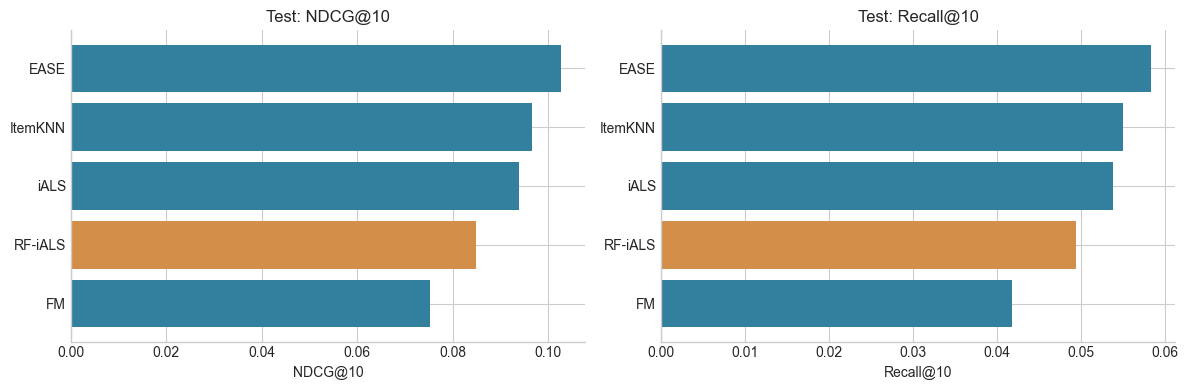

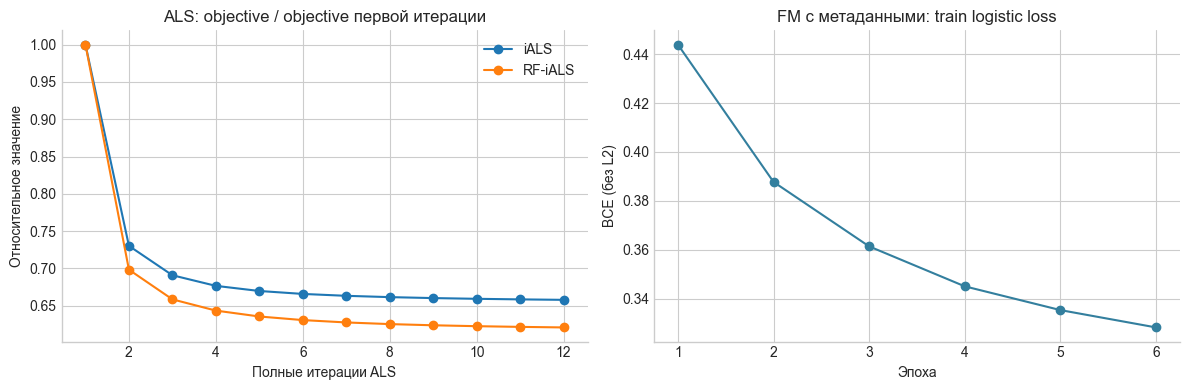

749

In [9]:
# Единственная финальная оценка заранее заданной абляции.
fm_id_final = fit_model('FM', ablation_params, final_train, final_features)
ablation_test, ablation_per_user, _ = evaluate(fm_id_final, final_train, test_users, test_truth)
per_user_test['FM ID-only'] = ablation_per_user
del fm_id_final
fm_meta_test = results.set_index('model').loc['FM']
ablation_table = pd.DataFrame([
    {'variant': 'FM metadata', **{m: fm_meta_test[m] for m in ablation_test}},
    {'variant': 'FM ID-only', **ablation_test}])
display(ablation_table)
ablation_table.to_csv('results/fm_ablation.csv', index=False)

def ndcg_vector(name):
    return per_user_test[name].set_index('user').loc[test_users, 'NDCG@10'].to_numpy()
comparisons = []
for a, b in [('RF-iALS', 'iALS'), ('FM', 'FM ID-only'),
             (results.iloc[0]['model'], results.iloc[1]['model'])]:
    comparisons.append({'comparison': f'{a} minus {b}', **paired_bootstrap(ndcg_vector(a), ndcg_vector(b))})
ci_table = pd.DataFrame(comparisons)
display(ci_table)
ci_table.to_csv('results/paired_bootstrap.csv', index=False)
print('95% paired bootstrap CI: 2000 повторов по пользователям, seed=42; условно на обученных моделях.')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, metric in zip(axes, ['NDCG@10', 'Recall@10']):
    ordered = results.sort_values(metric)
    axis.barh(ordered.model, ordered[metric], color=['#337f9e' if n != 'RF-iALS' else '#d38f49' for n in ordered.model])
    axis.set(title=f'Test: {metric}', xlabel=metric)
fig.tight_layout()
fig.savefig('figures/test_comparison.png', dpi=180)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in ['iALS', 'RF-iALS']:
    values = np.array(final_curves[name])
    axes[0].plot(np.arange(1, len(values)+1), values / values[0], marker='o', label=name)
axes[0].set(title='ALS: objective / objective первой итерации', xlabel='Полные итерации ALS', ylabel='Относительное значение')
axes[0].legend()
axes[1].plot(np.arange(1, len(final_curves['FM'])+1), final_curves['FM'], marker='o', color='#337f9e')
axes[1].set(title='FM с метаданными: train logistic loss', xlabel='Эпоха', ylabel='BCE (без L2)')
fig.tight_layout()
fig.savefig('figures/training_curves.png', dpi=160)
plt.show()
Path('results/training_curves.json').write_text(json.dumps(final_curves, indent=2))

## 6. Выводы по полученным результатам

Следующая ячейка формирует численные выводы непосредственно из финальной таблицы и парных сравнений.
Интервалы не включают неопределённость от других seed, смены временного окна или полного повторного обучения.

In [10]:
by_model = results.set_index('model')
winner = results.iloc[0]
rf_delta = by_model.loc['RF-iALS', 'NDCG@10'] - by_model.loc['iALS', 'NDCG@10']
fm_delta = by_model.loc['FM', 'NDCG@10'] - ablation_test['NDCG@10']
rf_pct = 100 * rf_delta / by_model.loc['iALS', 'NDCG@10']
fm_pct = 100 * fm_delta / ablation_test['NDCG@10']
rf_ci, fm_ci = ci_table.iloc[0], ci_table.iloc[1]
text = f"""
**Лучший метод на test — {winner['model']}**: NDCG@10 = {winner['NDCG@10']:.4f},
Recall@10 = {winner['Recall@10']:.4f}, Precision@10 = {winner['Precision@10']:.4f}.
Его настройки: `{winner['params']}`. Модель с лучшим NDCG не обязательно имеет лучшую полноту или охват: все показатели приведены в общей таблице.

**Собственный сигнал:** RF-iALS минус iALS по NDCG@10 = {rf_delta:+.4f} ({rf_pct:+.1f}%),
95% парный CI [{rf_ci['ci_low']:+.4f}; {rf_ci['ci_high']:+.4f}].
Период полураспада выбран по validation: {selected['RF-iALS']['half_life']:.0f} дней.
Здесь {'гипотеза о пользе текущего интереса поддержана положительной разницей' if rf_delta > 0 else 'ослабление старых и разовых покупок не улучшило перенос интереса на новые товары'}.
Это сравнение при одинаковых confidence, ранге, регуляризации, числе итераций и seed: эффект связан с заменой целевого p.

**Метаданные FM:** разница относительно контрольной FM с ID = {fm_delta:+.4f} ({fm_pct:+.1f}%),
95% парный CI [{fm_ci['ci_low']:+.4f}; {fm_ci['ci_high']:+.4f}].
В данном бюджете {'добавление исторических метаданных улучшило NDCG' if fm_delta > 0 else 'метаданные не дали улучшения NDCG; дополнительные признаки и короткое обучение могли осложнить оптимизацию'}.
Сравнение совместное; вклад страны, цены и отдельных слов по этим результатам разделить нельзя.

**Ограничения.** Один магазин, один год, преобладание Великобритании и наличие оптовиков ограничивают обобщение.
Успешная покупка не равна удовлетворённости, отсутствие покупки не равно отрицательному отзыву.
Протокол оценивает новые товары для уже известных активных клиентов ({len(test_users)} пользователей на test),
исключая повторы, cold-start и пользователей без новых покупок; это не метрика для всей аудитории магазина.
Покупки после конца окна не учитываются, а остатки товаров и показы витрины неизвестны.
У всех кандидатов была историческая покупка, но наличие на складе в дату рекомендации не гарантировано.
Подбор небольшой и выполнен при одном seed; особенно FM может выиграть от другого бюджета, это не проверялось по test.
Парный bootstrap характеризует вариацию по клиентам, но не учитывает общие товарные и временные зависимости.
Сезонность осени и новогодних товаров означает, что нужен дополнительный rolling-window эксперимент для выводов о других сезонах.
"""
display(Markdown(text))
Path('results/conclusions.md').write_text(text.strip() + '\n', encoding='utf-8')


**Лучший метод на test — EASE**: NDCG@10 = 0.1026,
Recall@10 = 0.0583, Precision@10 = 0.0877.
Его настройки: `{"reg": 1000.0}`. Модель с лучшим NDCG не обязательно имеет лучшую полноту или охват: все показатели приведены в общей таблице.

**Собственный сигнал:** RF-iALS минус iALS по NDCG@10 = -0.0090 (-9.6%),
95% парный CI [-0.0147; -0.0035].
Период полураспада выбран по validation: 180 дней.
Здесь ослабление старых и разовых покупок не улучшило перенос интереса на новые товары.
Это сравнение при одинаковых confidence, ранге, регуляризации, числе итераций и seed: эффект связан с заменой целевого p.

**Метаданные FM:** разница относительно контрольной FM с ID = -0.0019 (-2.5%),
95% парный CI [-0.0070; +0.0032].
В данном бюджете метаданные не дали улучшения NDCG; дополнительные признаки и короткое обучение могли осложнить оптимизацию.
Сравнение совместное; вклад страны, цены и отдельных слов по этим результатам разделить нельзя.

**Ограничения.** Один магазин, один год, преобладание Великобритании и наличие оптовиков ограничивают обобщение.
Успешная покупка не равна удовлетворённости, отсутствие покупки не равно отрицательному отзыву.
Протокол оценивает новые товары для уже известных активных клиентов (1587 пользователей на test),
исключая повторы, cold-start и пользователей без новых покупок; это не метрика для всей аудитории магазина.
Покупки после конца окна не учитываются, а остатки товаров и показы витрины неизвестны.
У всех кандидатов была историческая покупка, но наличие на складе в дату рекомендации не гарантировано.
Подбор небольшой и выполнен при одном seed; особенно FM может выиграть от другого бюджета, это не проверялось по test.
Парный bootstrap характеризует вариацию по клиентам, но не учитывает общие товарные и временные зависимости.
Сезонность осени и новогодних товаров означает, что нужен дополнительный rolling-window эксперимент для выводов о других сезонах.


1908

## Проверка воспроизводимости и состава работы

Фиксированы: источник и SHA256, правила очистки, календарные границы, критерии warm-start,
полный каталог и маска истории, seed=42, число потоков, версии основных библиотек,
все пространства поиска и выбранные параметры. Параметры не меняются после test.
На другом CPU/BLAS возможны небольшие численные отклонения, поэтому побитовая идентичность между платформами не гарантируется.

В `results/` находятся агрегированные CSV/JSON и текст выводов, в `figures/` — графики.
В `tests/` проверяются нормальные уравнения с небинарным p, уменьшение ALS objective,
стационарность EASE, FM по явной формуле пар, быстрый FM scoring, метрики и исключение известных объектов.
Исходные данные, окружение и обученные веса исключены через `.gitignore`.